✅
TASK 2: Unemployment Analysis with Python 
● Analyze unemployment rate data representing unemployed people percentage. 
● Use Python for data cleaning, exploration, and visualization of unemployment trends. 
● Investigate the impact of Covid-19 on unemployment rates. 
● Identify key patterns or seasonal trends in the data. 
● Present insights that could inform economic or social policies

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load dataset
df = pd.read_csv("Unemployment in India.csv")

In [5]:
print(df)

             Region         Date  Frequency   Estimated Unemployment Rate (%)  \
0    Andhra Pradesh   31-05-2019    Monthly                              3.65   
1    Andhra Pradesh   30-06-2019    Monthly                              3.05   
2    Andhra Pradesh   31-07-2019    Monthly                              3.75   
3    Andhra Pradesh   31-08-2019    Monthly                              3.32   
4    Andhra Pradesh   30-09-2019    Monthly                              5.17   
..              ...          ...        ...                               ...   
763             NaN          NaN        NaN                               NaN   
764             NaN          NaN        NaN                               NaN   
765             NaN          NaN        NaN                               NaN   
766             NaN          NaN        NaN                               NaN   
767             NaN          NaN        NaN                               NaN   

      Estimated Employed   

In [7]:
# Clean column names
df.columns = df.columns.str.strip()

In [9]:
df

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural
...,...,...,...,...,...,...,...
763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
764,NaN,NaN,NaN,NaN,NaN,NaN,NaN
765,NaN,NaN,NaN,NaN,NaN,NaN,NaN
766,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# Display first five rows
print("First five rows:")
print(df.head())

First five rows:
           Region         Date Frequency  Estimated Unemployment Rate (%)  \
0  Andhra Pradesh   31-05-2019   Monthly                             3.65   
1  Andhra Pradesh   30-06-2019   Monthly                             3.05   
2  Andhra Pradesh   31-07-2019   Monthly                             3.75   
3  Andhra Pradesh   31-08-2019   Monthly                             3.32   
4  Andhra Pradesh   30-09-2019   Monthly                             5.17   

   Estimated Employed  Estimated Labour Participation Rate (%)   Area  
0          11999139.0                                    43.24  Rural  
1          11755881.0                                    42.05  Rural  
2          12086707.0                                    43.50  Rural  
3          12285693.0                                    43.97  Rural  
4          12256762.0                                    44.68  Rural  


In [13]:
# Check dataset information
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    object 
 1   Date                                     740 non-null    object 
 2   Frequency                                740 non-null    object 
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [15]:
# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64


In [17]:
# Remove missing values and duplicates
df = df.dropna().drop_duplicates()

In [19]:
# Convert date column
df["Date"] = pd.to_datetime(
    df["Date"].astype(str).str.strip(),
    dayfirst=True,
    errors="coerce"
)

In [21]:
df = df.dropna(subset=["Date"])

In [23]:
# Clean unemployment rate column
rate_col = "Estimated Unemployment Rate (%)"
df[rate_col] = pd.to_numeric(df[rate_col], errors="coerce")
df = df.dropna(subset=[rate_col])

In [25]:
# Display summary statistics
print("\nSummary Statistics:")
print(df[rate_col].describe())


Summary Statistics:
count    740.000000
mean      11.787946
std       10.721298
min        0.000000
25%        4.657500
50%        8.350000
75%       15.887500
max       76.740000
Name: Estimated Unemployment Rate (%), dtype: float64


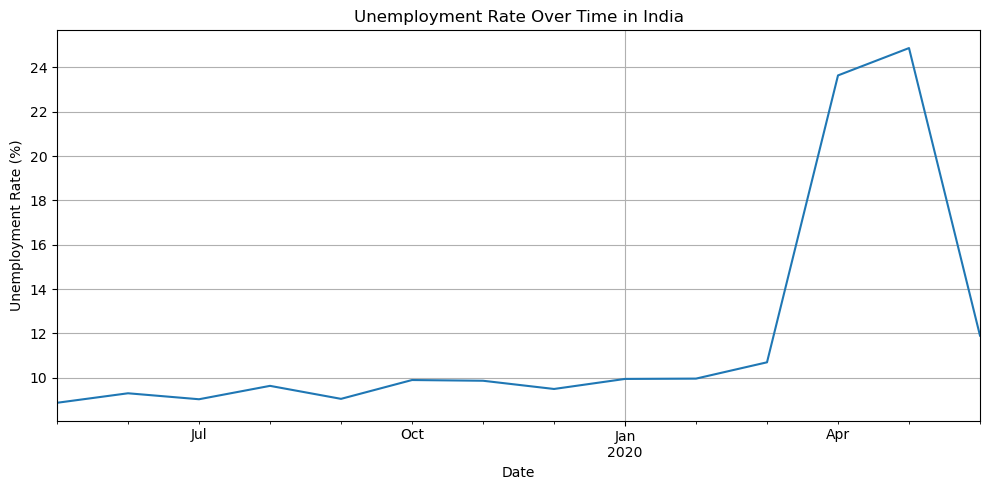

In [27]:
# 1. Unemployment trend over time
trend = df.groupby("Date")[rate_col].mean()

plt.figure(figsize=(10, 5))
trend.plot()
plt.title("Unemployment Rate Over Time in India")
plt.xlabel("Date")
plt.ylabel("Unemployment Rate (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
# 2. COVID-19 impact analysis
df["Period"] = df["Date"].apply(
    lambda date: "Before COVID-19"
    if date < pd.Timestamp("2020-03-25")
    else "During/After COVID-19"
)

In [31]:
covid = df.groupby("Period")[rate_col].mean()

print("\nAverage Unemployment Rate:")
print(covid)


Average Unemployment Rate:
Period
Before COVID-19           9.509534
During/After COVID-19    17.774363
Name: Estimated Unemployment Rate (%), dtype: float64


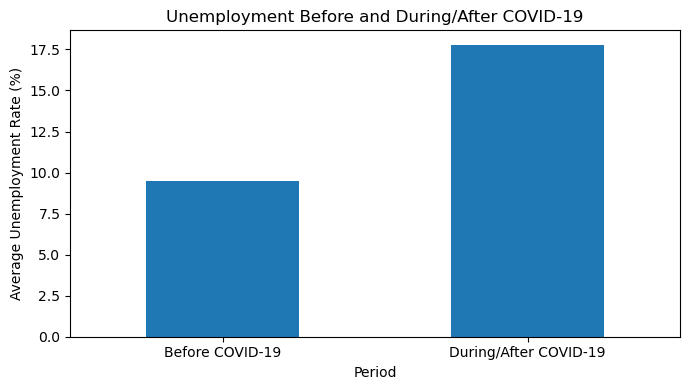

In [33]:
covid.plot(kind="bar", figsize=(7, 4))
plt.title("Unemployment Before and During/After COVID-19")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

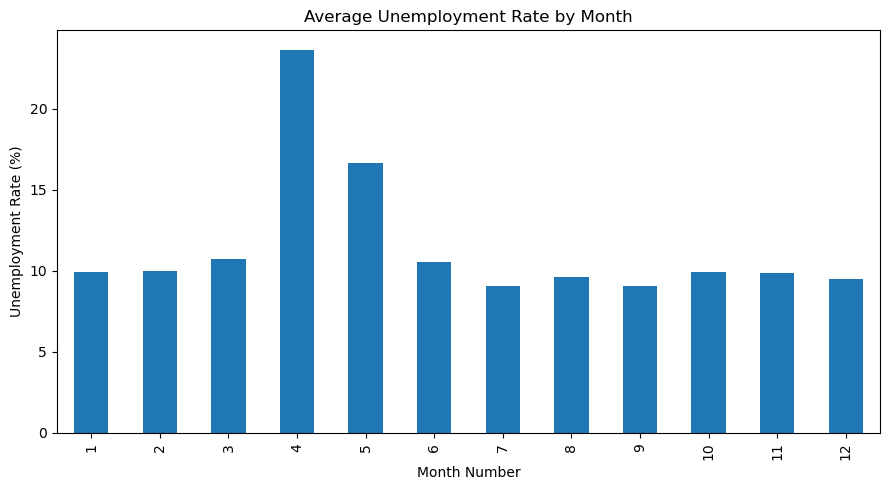

In [35]:
# 3. Monthly pattern analysis
df["Month"] = df["Date"].dt.month

monthly = df.groupby("Month")[rate_col].mean()

monthly.plot(kind="bar", figsize=(9, 5))
plt.title("Average Unemployment Rate by Month")
plt.xlabel("Month Number")
plt.ylabel("Unemployment Rate (%)")
plt.tight_layout()
plt.show()


Average Unemployment by Area:
Area
Rural    10.324791
Urban    13.166614
Name: Estimated Unemployment Rate (%), dtype: float64


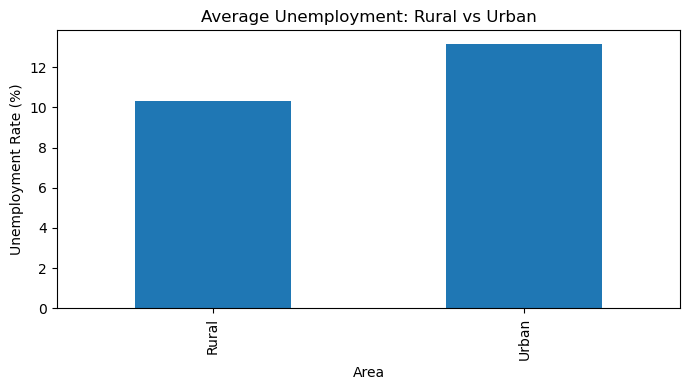


Analysis completed successfully!


In [41]:
# 4. Rural vs Urban analysis
if "Area" in df.columns:
    area_trend = df.groupby("Area")[rate_col].mean()

    print("\nAverage Unemployment by Area:")
    print(area_trend)
    
    area_trend.plot(kind="bar", figsize=(7, 4))
    plt.title("Average Unemployment: Rural vs Urban")
    plt.ylabel("Unemployment Rate (%)")
    plt.tight_layout()
    plt.show()

print("\nAnalysis completed successfully!")